# What the models were shown during training

**The question** (2026-10-30): "search for the training data in each timestep of the training". The four parts
chosen:
1. a tool that finds the training windows of any update of any saved run (`training_data.py`);
2. the windows of chosen updates: the first 10, the start, middle and end of training, and the updates where the
   training loss jumped most;
3. statistics over all of training, for the 39 window streams of the saved runs:
   * how often each true state occurs at each position;
   * how many windows repeat;
   * how many different token histories were seen;
   * whether the training loss of each update follows what that update's batch contained;
4. for each position in a window, what each model reads and what its loss scores.

**The idea.** No run saves its training windows, but every window can be made again exactly.
* Each update draws 128 new windows from one stream of random numbers, and always uses the same amount of that stream.
  So the windows of any update can be reached directly, by skipping the stream forward (section 2).
* The windows depend only on the process, the seed, the batch size and the window length. So every model trained on
  the same process with the same seed saw exactly the same windows, update by update (section 3).
* The true process gives the exact probability of every token of every window. So for each update, the batch's own
  unpredictability (its exact cross-entropy, CE) can be set beside the training loss (sections 5.3 and 6.4).

**Summary**

* **The windows can be found again exactly.** No run saves its windows, but every update's 128 windows can be made
  again. The sampler state saved with 184 of the 185 checkpoints of the 171 saved runs equals the skip; the 185th,
  section 13's, saved none. Training the 300-update model-2 run again on the found windows gives its saved losses
  exactly at all 300 updates (section 2).
* **Many runs saw the same windows.** The 170 verified runs share 39 window streams (13 processes × 3 seeds). For
  example, 19 runs saw exactly the renewal-15 seed-0 windows (section 3).
* **At every scored position the true state is known** from the tokens before it, in every process: the flowers'
  after 1 token, renewal-N's after N − 1, always before the first scored token (section 4).
* **The windows are what the process says they should be.**
  * The true states at each position follow the long-run distribution: 12 of 2,829 position tests are below
    p = 0.01, about what chance gives.
  * The number of equal window pairs matches the process's prediction within about 1%.
  * Low-entropy processes repeat a lot: 11–13% of renewal-15's windows and 72–74% of its 40-token histories repeat
    an earlier one. No flower window ever repeats (6.1, 6.2).
* **The models saw almost every short context they are tested on.** For every renewal process, at least 99.95% of
  the test windows' words of up to 20 tokens appeared in training. At the de Bruijn models' orders the share is
  99.6–100% (6.3).
* **A trained model's loss follows its batch.** Over the last 10,000 updates, the batch's own exact CE goes with a
  median 96% of the update-to-update variation of a training CE term (234 run-terms). The better the model has
  learned, the higher the share: 99.3% for terms within 0.01 bits of the exact CE, 61% for terms more than 0.1 bits
  above it. In the first 1,000 updates the share is 1%: there the loss falls with learning (6.4).
* **Most loss jumps are hard batches; the biggest are not.**
  * For the CE part of the loss, 65% of each run's three largest jumps came with a batch at least 3 spreads above
    its running median.
  * On 731 updates, two or more runs of the same stream jumped together, and 98.5% of those batches were harder than
    average.
  * The whole loss's largest jumps are model B's copy term (up to 98 bits), and the largest CE jumps are spikes in
    the middle of training. Neither follows the batch (5.3).

**Sections**
1. Setup.
2. How the windows are made and found again.
3. Which runs saw the same windows.
4. What each model reads and is scored on at each position.
5. The windows of chosen updates: 5.1 the first 10 updates; 5.2 start, middle and end; 5.3 the biggest loss jumps.
6. Statistics over training: 6.1 the true states at each position; 6.2 repeated windows; 6.3 how many different
   histories were seen; 6.4 the training loss and what each batch contained.
7. Findings.

The statistics are computed by `python training_data.py stats` (14.8 CPU-hours for the 39 streams, at most 62 minutes for one) into `runs/training_data/`; this
notebook only reads them. `tests/test_training_data.py` checks the tool and the counts (38 tests).

## 1. Setup

The cell above loads the saved runs (`runs/model_*/` and `runs/imported/`), groups them by the windows they were
trained on, and reads the saved statistics.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # run this notebook from test_models/

import json
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

import process as P
import training as TR
import training_data as TD

TD.style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
FIGURES = TD.STATS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
FOLDERS = TD.run_folders()
STREAMS = TD.streams()
TABLE = TD.stream_table()
STATS = {label: TD.load_statistics(label) for label in TABLE["stream"] if (TD.STATS / f"{label}.json").exists()}
LABEL = {f: TD.stream_label(TD.stream_key(TR.read_settings(f))) for f in FOLDERS}
WITH_STATS = [f for f in FOLDERS if LABEL[f] in STATS]
print(f"{len(FOLDERS)} saved runs in {len(STREAMS)} window streams; statistics saved for {len(STATS)} streams "
      f"({len(WITH_STATS)} runs)")


def stream_of(label):
    # the run folders of one stream
    return next(v for k, v in STREAMS.items() if TD.stream_label(k) == label)


def group_of(name):
    return "renewal" if name.startswith("renewal") else \
        "flower, read backward" if "backward" in name else "flower, read forward"


175 saved runs in 40 window streams; statistics saved for 39 streams (174 runs)


## 2. How the windows are made, and how to find them again

**How they are made.** At every update, `training.train()` (`training.py:386`) calls `train_source.draw(128, T)`.
`train_source` is one window sampler, `process.sampler(train_seed)`, made once at the start of training
(`training.py:359`), with `train_seed` = 1101 + the run's seed. `training.extend()` carries on with the same sampler
from its saved state (`training.py:486–487`). Each call of `WindowSampler.draw` (`process.py:1423–1436`):
1. draws a starting state for each of the 128 windows from the long-run distribution of the generating machine's
   states (one random number per window);
2. then, at each of the T positions, draws each window's token and next state from the machine (one random number
   per window and position).

So every update uses exactly 128 × (T + 1) random numbers. The runs keep only settings, parameters and measurements,
not the windows (`walkthrough.ipynb`, section 4).

**How they are found again.** The random numbers come from numpy's PCG64 generator, a permuted congruential
generator (O'Neill 2014). Its state can be moved forward any number of steps without making the numbers in between
(numpy: `advance` moves the generator on "as-if delta draws have occurred"). So the windows of update k are the next
draw after skipping (k − 1) × 128 × (T + 1) numbers: `TD.windows_at(run, k)`. numpy does not promise that each
random number from `random()` or `choice()` is exactly one draw, so the cells below test it:
* the skip against drawing every update in order;
* the sampler state each run saved after training against the skip, for every saved run;
* training a run again on the found windows, which must reproduce its saved training losses exactly.

**Results** (cells below)
* **The skip gives the windows of drawing every update in order.** Checked at updates 1, 2, 3, 1,000 and 75,000.
  Drawing all 75,000 updates in order took about two minutes, the skip a few milliseconds.
* **Every run used those windows, in order.** The sampler state saved after training equals the skip at 184 of the
  185 checkpoints of all 171 saved runs, including the 14 continuations to 75,000 or 100,000 updates. The exception is
  section 13's run (model 1_L2, 300 + 40 tokens), which saved no sampler state. Its windows cannot be verified, so it
  is left out of the statistics below.
* **The losses come out the same.** The 300-update model-2 run, trained again on the found windows, gives its saved
  loss and terms exactly at all 300 updates. On the next update's windows it matches at none (largest difference
  0.073 bits).

In [2]:
run = TR.RUNS / "imported/model_2/renewal-15_w0_s0_section16"     # section 16's model 2, seed 0
s = TR.read_settings(run)
print(f"random numbers per update: {TD.numbers_per_update(s):,} = batch {s.batch_size} x (window {s.total_len} + 1)")
x, st = TD.windows_at(run, 1, states=True)
print(f"update 1: tokens {tuple(x.shape)}, true states {st.shape} (the state before each token, and after the last)")
start = time.perf_counter()
sampler = s.process_object().sampler(s.train_seed)
for k in range(1, TD.last_update(run) + 1):
    drawn = sampler.draw(s.batch_size, s.total_len)
    if k in (1, 2, 3, 1000, TD.last_update(run)):
        print(f"update {k:>6,}: the skip gives the windows of drawing in order: {torch.equal(drawn, TD.windows_at(run, k))}")
print(f"drawing all {TD.last_update(run):,} updates in order took {time.perf_counter() - start:.0f} s")
start = time.perf_counter()
TD.windows_at(run, TD.last_update(run))
print(f"the skip to update {TD.last_update(run):,} took {time.perf_counter() - start:.3f} s")

random numbers per update: 7,808 = batch 128 x (window 60 + 1)
update 1: tokens (128, 60), true states (128, 61) (the state before each token, and after the last)
update      1: the skip gives the windows of drawing in order: True
update      2: the skip gives the windows of drawing in order: True
update      3: the skip gives the windows of drawing in order: True


update  1,000: the skip gives the windows of drawing in order: True


update 75,000: the skip gives the windows of drawing in order: True
drawing all 75,000 updates in order took 103 s
the skip to update 75,000 took 0.003 s


In [3]:
checks = {f: TD.check_run(f) for f in FOLDERS}
check_table = pd.DataFrame([dict(run=TD.run_name(f), checkpoint=c, updates=TR.read_settings(f).steps if c == "completed.pt"
                                 else int(c.split("_")[1].split(".")[0]), matches=ok)
                            for f, r in checks.items() for c, ok in r.items()])
print("saved sampler state equals the skip (True), differs (False), or was not saved (None):")
print(check_table["matches"].astype(str).value_counts().to_string())
print(f"checkpoints checked: {len(check_table)} in {len(FOLDERS)} runs, of which "
      f"{(check_table['checkpoint'] != 'completed.pt').sum()} are continuations")
display(check_table[check_table["matches"] != True])

saved sampler state equals the skip (True), differs (False), or was not saved (None):
matches
True    188
checkpoints checked: 189 in 175 runs, of which 14 are continuations


,run,checkpoint,updates,matches
135,1_L2 | renewal-15 | w0.03 | seed 0 | section 13 (renewal15_1ee548972375),completed.pt,50000,None


In [4]:
replay_run = next(f for f in FOLDERS if TR.read_settings(f).steps == 300 and TR.read_settings(f).model == "2"
                  and TR.run_folder(TR.read_settings(f)).name == f.name)     # made with the current code
s = TR.read_settings(replay_run)
saved = pd.read_csv(replay_run / "training_history.csv")
found = [TD.windows_at(s, k) for k in range(1, s.steps + 2)]      # Settings: update 301 too, for the shifted control
original = P.Process.sampler


class Replay:
    # hands train() the windows found by windows_at, shifted by `shift` updates, instead of drawing them
    def __init__(self, shift):
        self.k, self.shift, self.rng = 0, shift, np.random.default_rng(0)

    def draw(self, batch_size, total_len, states=False):
        self.k += 1
        return found[self.k - 1 + self.shift]


replayed = {}
for shift in (0, 1):
    P.Process.sampler = lambda self, seed, shift=shift: Replay(shift) if seed == s.train_seed else original(self, seed)
    try:
        with tempfile.TemporaryDirectory() as tmp:
            TR.train(s, folder=Path(tmp) / "again", force=True, verbose=False)
            replayed[shift] = pd.read_csv(Path(tmp) / "again" / "training_history.csv")
    finally:
        P.Process.sampler = original
columns = ["ce_gru", "ce_t1", "loss"]
print(f"{replay_run.relative_to(TR.RUNS)}: {s.steps} updates trained again")
for shift, h in replayed.items():
    equal = (h[columns].to_numpy() == saved[columns].to_numpy()).all(axis=1)
    print(f"  on the windows of update k + {shift}: loss and terms identical at {equal.sum()} of {len(equal)} updates; "
          f"largest loss difference {np.abs(h['loss'] - saved['loss']).max():.3g} bits")
display(pd.DataFrame({"saved training loss": saved["loss"].to_numpy()[:5],
                      "trained again on the found windows": replayed[0]["loss"].to_numpy()[:5],
                      "trained on the next update's windows": replayed[1]["loss"].to_numpy()[:5]},
                     index=pd.Index(range(1, 6), name="update")))

model_2/renewal-15_w0_n300_s0_68206511d4: 300 updates trained again
  on the windows of update k + 0: loss and terms identical at 300 of 300 updates; largest loss difference 0 bits
  on the windows of update k + 1: loss and terms identical at 0 of 300 updates; largest loss difference 0.073 bits


,saved training loss,trained again on the found windows,trained on the next update's windows
update,,,
1,2.126230,2.126230,2.127531
2,2.107020,2.107020,2.105521
3,2.085501,2.085501,2.086984
4,2.066836,2.066836,2.066395
5,2.046586,2.046586,2.046341


## 3. Which runs saw the same windows

A stream is the windows of one (process, parameters, `train_seed`, batch size, window length). Every run of a stream
was trained on exactly the same windows at every update, whatever its model. The table lists the streams; `models`
names the model files whose runs used each.

**Results**
* **39 streams.** The 170 verified runs share 39 streams: 13 processes × 3 seeds.
* **Example.** The 19 runs listed under the table all saw the same windows: section 16's and 17's seed-0 runs, both
  de Bruijn models and the two 300-update runs of model 2.
* **Two processes share a name.** Both are labelled flower-9 by their number of states: 8 dice of 12 faces
  (sections 7–9) and 8 dice of 14 faces (the de Bruijn runs). Here they are told apart by their parameters.
* **Different processes share random numbers.** The same seed gives every process the same random numbers, so even
  different processes' windows are related. Every forward flower with the same seed has the same hub-and-petal rhythm
  in every window (6.1).

In [5]:
display(TABLE.drop(columns="stream").set_index(["process", "seed"]))
print("The runs trained on renewal-15, seed 0, 60-token windows (one stream):")
for f in stream_of("renewal-15_T60_B128_seed1101"):
    print("  ", TD.run_name(f), f"({TD.last_update(f):,} updates)")

window  batch  last_update  runs                                                                           models
process                   seed                                                                                                                   
flower-13-backward_n8m12  0         60    128        50000     5                                     5b, B, C, discrete_Transformer, feedback_GRU
                          1         60    128        50000     5                                     5b, B, C, discrete_Transformer, feedback_GRU
                          2         60    128        50000     5                                     5b, B, C, discrete_Transformer, feedback_GRU
flower-15-backward_n8m14  0         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          1         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          2         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
flower-21_n20m30          0         60    128        50000     4                                        5b, B, discrete_Transformer, feedback_GRU
                          1         60    128        50000     4                                        5b, B, discrete_Transformer, feedback_GRU
                          2         60    128        50000     4                                        5b, B, discrete_Transformer, feedback_GRU
flower-31-backward_n20m30 0         60    128        50000     4                                        5b, B, discrete_Transformer, feedback_GRU
                          1         60    128        50000     4                                        5b, B, discrete_Transformer, feedback_GRU
                          2         60    128        50000     4                                        5b, B, discrete_Transformer, feedback_GRU
flower-4_n3m5             0         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          1         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          2         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
flower-6-backward_n3m5    0         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          1         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          2         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
flower-9_n8m12            0         60    128        50000     5                                     5b, B, C, discrete_Transformer, feedback_GRU
                          1         60    128        50000     5                                     5b, B, C, discrete_Transformer, feedback_GRU
                          2         60    128        50000     5                                     5b, B, C, discrete_Transformer, feedback_GRU
flower-9_n8m14            0         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          1         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          2         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
renewal-10                0         60    128        50000     2                                                         de_bruijn, de_bruijn_bic
                          1         60    128        50000     2                          

The runs trained on renewal-15, seed 0, 60-token windows (one stream):
   1 | renewal-15 | w0 | seed 0 | test_models setup, original setup (50,000 updates)
   1 | renewal-15 | w0 | seed 0 | test_models section16 (50,000 updates)
   2 | renewal-15 | w0 | seed 0 | test_models 68206511d4 (300 updates)
   2 | renewal-15 | w0 | seed 0 | test_models 83ef5ee6af (300 updates)
   de_bruijn | renewal-15 | w1 | seed 0 | test_models 0de47cf064 (50,000 updates)
   de_bruijn_bic | renewal-15 | w1 | seed 0 | test_models 09b043fb69 (50,000 updates)
   1 | renewal-15 | w0 | seed 0 | section 16 (gru_loss), original setup (50,000 updates)
   1 | renewal-15 | w0 | seed 0 | section 16 (gru_loss) (50,000 updates)
   2 | renewal-15 | w0 | seed 0 | section 16 (both_losses) (75,000 updates)
   2_L2 | renewal-15 | w0.01 | seed 0 | section 17 (l2_both_losses) (50,000 updates)
   2_L2 | renewal-15 | w0.03 | seed 0 | section 17 (l2_both_losses) (50,000 updates)
   2_L2 | renewal-15 | w0.1 | seed 0 | section 17 (l2

## 4. What each model reads and is scored on at each position

A window has T tokens at positions 0 to T − 1. With the usual settings (renewal-5, -10 and -15 and every flower)
T = 60:
* positions 0–39 are the history (`history_len` H = 40);
* positions 40–59 are the future (`rollout_len` 20);
* `context` C = 19.

Renewal-30's windows have 60 + 30 tokens with C = 29, and renewal-60's 120 + 60 with C = 59.

**What each part reads**
* **The Transformer** of a hybrid (models 1 to C) reads the whole window with causal attention. Its state at
  position t depends on tokens 0 to t only, and predicts token t + 1.
* **The GRU** of a hybrid (models 1, 1_L2, 2, 2_L2, 3, 5a, A and B):
  1. it starts from the Transformer's state at position H − 1, after the 40 history tokens (the handoff, dashed line
     in the figure);
  2. that state predicts token H;
  3. the GRU then reads the real token H to make its next state, and so on.

  So it reads tokens H to T − 2 and predicts tokens H to T − 1.
* **The feedback GRU and the discrete Transformer** read tokens 0 to T − 2, the GRU from a blank start. Their state
  at t predicts token t + 1.
* **The de Bruijn models** read only the last R tokens at each position (R is the order; table below).

**What each loss scores.** The figure below shows, for renewal-15's windows, each term of each model's loss and the
positions it uses. The model files' `loss()` methods are the source. A test (`tests/test_training_data.py`) checks
every next-token term against the model's own `predict()`: the same first token and the same number of tokens, for
all 15 model files.
* `ce_gru`: the 20 future tokens, 40–59.
* `ce_t1` and `ce`: tokens 20–59. The state at 19 predicts token 20, so C + 1 = 20 is the first scored token.
* `ce_t2` and `ce_t3`: the pairs and triples of tokens that start at 20.
* `pred` (the de Bruijn models): tokens R to 59.
* The other terms act on the chosen states (purple).

**How to read the table.** In `uses`:
* `tokens` is the CE of those tokens;
* `tuples n` is the CE of n tokens in a row, predicted at those positions;
* `states` is a term on the states chosen there;
* `targets` means the state chosen there is the target.

**The de Bruijn orders.** Renewal-N's Markov order is N − 1, and every flower's is 1. The order fitted to the data
(the BIC rule) is 4, 9, 10, 8–9 and 8 for renewal-5, -10, -15, -30 and -60, and 1 for every flower.

uses  first  last  positions
model                term                                              
1                    ce_gru              tokens     40    59         20
1_L2                 ce_gru              tokens     40    59         20
                     l2                  states     40    59         20
2                    ce_gru              tokens     40    59         20
                     ce_t1               tokens     20    59         40
2_L2                 ce_gru              tokens     40    59         20
                     ce_t1               tokens     20    59         40
                     l2                  states     40    58         19
3                    ce_gru              tokens     40    59         20
                     ce_t1               tokens     20    59         40
                     next_entropy        states     19    58         40
                     next_nll           targets     20    59         40
4                    ce_t1               tokens     20    59         40
                     next_entropy        states     19    58         40
                     next_nll           targets     20    59         40
5a                   ce_gru              tokens     40    59         20
                     ce_t1               tokens     20    59         40
                     ce_t2             tuples 2     19    57         39
                     inferred_entropy    states     19    57         39
5b                   ce_t1               tokens     20    59         40
                     ce_t2             tuples 2     19    57         39
                     inferred_entropy    states     19    57         39
A                    ce_gru              tokens     40    59         20
                     ce_t1               tokens     20    59         40
                     next_entropy        states     19    58         40
                     next_nll           targets     20    59         40
B                    ce_gru              tokens     40    59         20
                     copy_ce             states     39    39          1
C                    ce_t1               tokens     20    59         40
                     ce_t2             tuples 2     19    57         39
                     inferred_entropy    states     19    56         38
                     ce_t3             tuples 3     19    56         38
feedback_GRU         ce                  tokens     20    59         40
discrete_Transformer ce                  tokens     20    59         40
de_bruijn            pred                tokens     14    59         46
                     use                 states     13    58         46
                     fit                targets     14    59         46
                     commit             targets     14    59         46
de_bruijn_bic        pred                tokens     10    59         50
                     use                 states      9    58         50
                     fit                targets     10    59         50
                     commit             targets     10    59         50

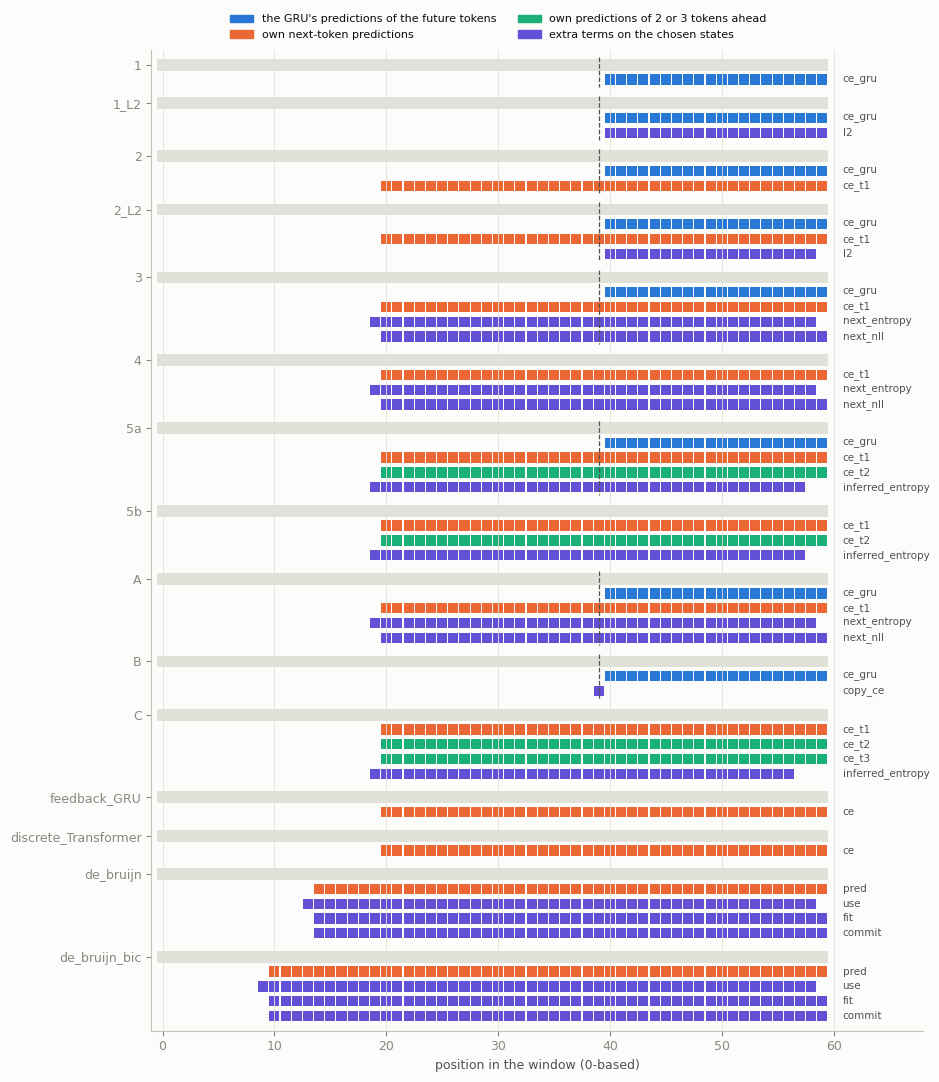

The de Bruijn models' order R in every stream they ran on (from the saved statistics):


run,de_bruijn,de_bruijn_bic
stream,,
flower-15-backward_n8m14_T60_B128_seed1101,1,1
flower-15-backward_n8m14_T60_B128_seed1102,1,1
flower-15-backward_n8m14_T60_B128_seed1103,1,1
flower-4_n3m5_T60_B128_seed1101,1,1
flower-4_n3m5_T60_B128_seed1102,1,1
flower-4_n3m5_T60_B128_seed1103,1,1
flower-6-backward_n3m5_T60_B128_seed1101,1,1
flower-6-backward_n3m5_T60_B128_seed1102,1,1
flower-6-backward_n3m5_T60_B128_seed1103,1,1


In [6]:
default = {m: TR.settings_for(m) for m in ["1", "1_L2", "2", "2_L2", "3", "4", "5a", "5b", "A", "B", "C",
                                           "feedback_GRU", "discrete_Transformer", "de_bruijn", "de_bruijn_bic"]}
orders = {m: TD.model_order(default[m]) for m in ("de_bruijn", "de_bruijn_bic")}      # renewal-15, seed 0
rows = []
for m, s in default.items():
    for term, (kind, positions) in TD.term_positions(s, orders.get(m)).items():
        rows.append(dict(model=m, term=term, uses=kind, first=positions[0], last=positions[-1], positions=len(positions)))
display(pd.DataFrame(rows).set_index(["model", "term"]))
fig = TD.plot_positions(default, orders)
fig.savefig(FIGURES / "positions.png", dpi=160, bbox_inches="tight")
plt.show()
print("The de Bruijn models' order R in every stream they ran on (from the saved statistics):")
display(pd.DataFrame([dict(stream=label, run=run.split("/")[0].replace("model_", ""), R=R)
                      for label, (info, _) in STATS.items() for run, R in info["de_bruijn_orders"].items()])
        .pivot(index="stream", columns="run", values="R"))

**What can be known at each position.** The true state behind a token can be known from the tokens before it only
once enough tokens have been read. The figure gives, for each process, the share of windows whose state after
tokens 0 to t is certain from those tokens (20,000 fresh windows per process, a random stream of their own; a dot
marks the state that predicts the first scored token). The table gives the first position where every window's
state is known.

**Results**
* Every flower's state is known after its first token.
* Renewal-N's state is known in every window after N − 1 tokens (positions 3, 8, 13, 28 and 58 for N = 5, 10, 15, 30
  and 60), because a run of N − 1 zeros or any 1 fixes it.
* So in every process, the state that predicts the first scored token is known in every window.

,window,first_position_where_all_are_known,first_scored_token,known_for_the_first_scored_token
process,,,,
renewal-15,60,13,20,1.0
flower-13-backward_n8m12,60,0,20,1.0
flower-21_n20m30,60,0,20,1.0
flower-31-backward_n20m30,60,0,20,1.0
flower-9_n8m12,60,0,20,1.0
flower-15-backward_n8m14,60,0,20,1.0
flower-4_n3m5,60,0,20,1.0
flower-6-backward_n3m5,60,0,20,1.0
flower-9_n8m14,60,0,20,1.0


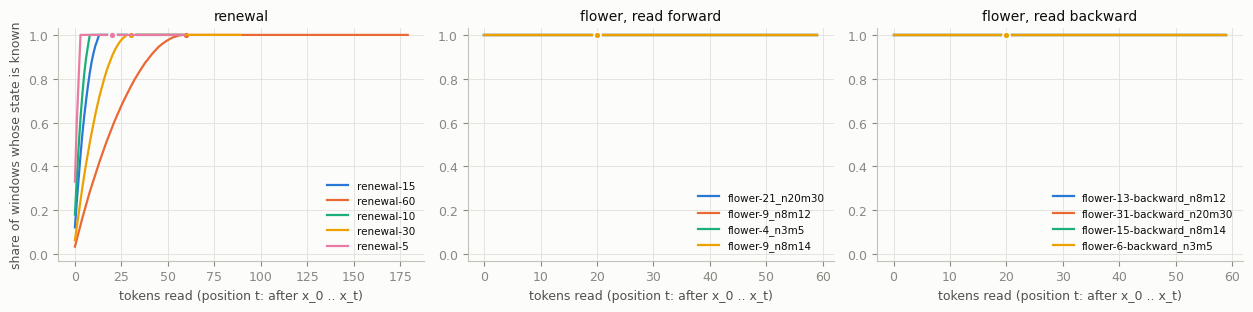

In [7]:
known, firsts, rows = {"renewal": {}, "flower, read forward": {}, "flower, read backward": {}}, {}, []
for key, folders in STREAMS.items():
    s = TR.read_settings(folders[0])
    if s.seed != 0 or TD.stream_label(key) not in STATS:
        continue
    name = TD.process_name(key)
    share = TD.known_share(s.process_object(), s.total_len)
    known[group_of(name)][name] = share
    firsts[name] = s.context + 1
    rows.append(dict(process=name, window=s.total_len, first_position_where_all_are_known=int(np.argmax(share == 1)),
                     first_scored_token=s.context + 1, known_for_the_first_scored_token=float(share[s.context])))
display(pd.DataFrame(rows).set_index("process").sort_values("window"))
fig = TD.plot_known(known, firsts)
fig.savefig(FIGURES / "known_by_position.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. The windows of chosen updates

**How to read the windows.** Each window is two lines: its tokens, and under each token the true state the process
was in just before it. Each is one character: 0–9, then a–z for 10–35, then A–Z for 36–61.
* For renewal, state `a<c>` is c, the number of 0s since the last 1 (so `e` = 14), and a 1 sends it back to 0.
* For a flower, state `s<i>` is i.

The `|` marks stand before the first token the own-prediction CE scores (C + 1) and before the first future token
(H). `TD.show_windows(run, update, rows)` prints any update of any run; `TD.windows_at(run, update, states=True)`
returns the arrays.

### 5.1 The first 10 updates

Renewal-15, seed 0: the stream of section 16's and 17's seed-0 runs, both de Bruijn models and the 300-update model-2
runs (19 runs). First the windows, then every run's training loss at updates 1–10. Under it is the batch's exact
CE: for each term, the exact cross-entropy of the tokens it scores, i.e. what a model that knows the process would
score on that batch.

**Results**
* **Every network model's loss falls steadily** over these updates, by about 0.01 bits per update for each CE term
  (model 1: 1.063 → 0.975), whatever the batch. The batch's exact CE moves up and down by up to 0.03 bits between
  updates (0.469–0.499 bits per token on tokens 20–59), and the losses do not follow it.
* **They start far above it**, at about 1.06 bits per token for each CE term at update 1 against the batch's 0.49.
  Model B starts at 14.6 because of its copy term, weighted 3.
* **The de Bruijn models start close to it**, because they start from their counted machine. The one with the fitted
  order predicts at 0.507 bits against the batch's 0.489.
* **Runs of the same model on the same windows are identical.** Section 16's model 2 and the two 300-update model-2
  runs have the same loss at every one of these updates.

In [8]:
first_runs = stream_of("renewal-15_T60_B128_seed1101")
for k in range(1, 11):
    print(TD.show_windows(first_runs[0], k, rows=2), end="\n\n")

update 1 of renewal-15_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   00001000001000000000|00000100000000001000|00100000000000100000
states 0   abcde012345012345678|9abcde0123456789a012|3450123456789ab01234
tokens 1   00000000000010000000|00010000100000110000|00000000010000000000
states 1   0123456789abc0123456|789a0123401234500123|456789abcd0123456789

update 2 of renewal-15_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   00001001000100000000|10100000100000100000|00000000010010001001
states 0   12345012012301234567|80101234501234501234|56789abcde0120123012
tokens 1   01000001000000000000|00100000100000000000|01000000010000000000
states 1   340123450123456789ab|cde0123450123456789a|bc012345670123456789

update 3 of renewal-15_T60_B128_seed1101: the first 2 

In [9]:
info, arrays = STATS["renewal-15_T60_B128_seed1101"]
first10 = TD.losses_at(first_runs, range(1, 11), STATS["renewal-15_T60_B128_seed1101"])
print("Training loss (bits per scored token, summed over the loss's terms) at updates 1-10:")
display(first10.pivot(index="run", columns="update", values="loss").round(4))
print("The batch's exact CE of the tokens each term scores (bits per token):")
display(pd.DataFrame(arrays["exact_terms"][:10].T, index=info["exact_terms"], columns=range(1, 11)).round(4))
print("Every stream: the batch's exact CE over all its tokens at updates 1-10 (bits per token):")
display(pd.DataFrame({label: STATS[label][1]["exact_mean"][:10] for label in STATS},
                     index=pd.Index(range(1, 11), name="update")).T.round(4))

Training loss (bits per scored token, summed over the loss's terms) at updates 1-10:


update,1,2,3,4,5,6,7,8,9,10
run,,,,,,,,,,
1 | renewal-15 | w0 | seed 0 | section 16 (gru_loss),1.0631,1.0537,1.0425,1.0335,1.0235,1.0134,1.0038,0.9943,0.9849,0.9752
"1 | renewal-15 | w0 | seed 0 | section 16 (gru_loss), original setup",1.0631,1.0537,1.0425,1.0335,1.0235,1.0135,1.0038,0.9944,0.9851,0.9754
1 | renewal-15 | w0 | seed 0 | test_models section16,1.0631,1.0537,1.0425,1.0335,1.0235,1.0134,1.0038,0.9943,0.9849,0.9752
"1 | renewal-15 | w0 | seed 0 | test_models setup, original setup",1.0631,1.0537,1.0425,1.0335,1.0235,1.0135,1.0038,0.9944,0.9851,0.9754
2 | renewal-15 | w0 | seed 0 | section 16 (both_losses),2.1262,2.1070,2.0855,2.0668,2.0466,2.0268,2.0075,1.9884,1.9697,1.9501
2 | renewal-15 | w0 | seed 0 | test_models 68206511d4,2.1262,2.1070,2.0855,2.0668,2.0466,2.0268,2.0075,1.9884,1.9697,1.9501
2 | renewal-15 | w0 | seed 0 | test_models 83ef5ee6af,2.1262,2.1070,2.0855,2.0668,2.0466,2.0268,2.0075,1.9884,1.9697,1.9501
2_L2 | renewal-15 | w0.01 | seed 0 | section 17 (l2_both_losses),2.1281,2.1088,2.0873,2.0686,2.0484,2.0286,2.0093,1.9902,1.9715,1.9519
2_L2 | renewal-15 | w0.03 | seed 0 | section 17 (l2_both_losses),2.1317,2.1124,2.0909,2.0722,2.0519,2.0322,2.0129,1.9938,1.9750,1.9555


The batch's exact CE of the tokens each term scores (bits per token):


,1,2,3,4,5,6,7,8,9,10
ce_from20,0.4878,0.4801,0.4856,0.4783,0.4909,0.4857,0.4991,0.4784,0.4941,0.4687
ce_gru_from40,0.4844,0.4725,0.5032,0.4695,0.4789,0.4870,0.5031,0.4910,0.4987,0.4665
ce_t1_from20,0.4878,0.4801,0.4856,0.4783,0.4909,0.4857,0.4991,0.4784,0.4941,0.4687
ce_t2_C19,0.9718,0.9590,0.9734,0.9620,0.9819,0.9724,0.9975,0.9548,0.9933,0.9404
ce_t3_C19,1.4487,1.4399,1.4586,1.4493,1.4711,1.4609,1.4946,1.4333,1.4928,1.4135
pred_from10,0.4888,0.4888,0.4923,0.4840,0.4921,0.4907,0.4952,0.4767,0.4956,0.4792
pred_from14,0.4896,0.4751,0.4867,0.4839,0.4919,0.4872,0.4978,0.4794,0.4905,0.4767


Every stream: the batch's exact CE over all its tokens at updates 1-10 (bits per token):


update,1,2,3,4,5,6,7,8,9,10
flower-13-backward_n8m12_T60_B128_seed1101,3.0139,3.0296,3.0377,3.0300,3.0347,3.0488,3.0349,3.0316,3.0350,3.0335
flower-13-backward_n8m12_T60_B128_seed1102,3.0144,3.0400,3.0354,3.0285,3.0319,3.0103,3.0212,3.0286,3.0333,3.0167
flower-13-backward_n8m12_T60_B128_seed1103,3.0305,3.0314,3.0149,3.0368,3.0425,3.0250,3.0341,3.0304,3.0141,3.0306
flower-15-backward_n8m14_T60_B128_seed1101,3.1478,3.1555,3.1482,3.1427,3.1438,3.1488,3.1585,3.1568,3.1402,3.1576
flower-15-backward_n8m14_T60_B128_seed1102,3.1441,3.1441,3.1599,3.1373,3.1498,3.1546,3.1404,3.1622,3.1502,3.1503
flower-15-backward_n8m14_T60_B128_seed1103,3.1404,3.1616,3.1591,3.1381,3.1530,3.1505,3.1396,3.1247,3.1442,3.1406
flower-21_n20m30_T60_B128_seed1101,4.3611,4.3624,4.3511,4.3651,4.3483,4.3478,4.3664,4.3652,4.3606,4.3603
flower-21_n20m30_T60_B128_seed1102,4.3743,4.3391,4.3510,4.3603,4.3661,4.3594,4.3568,4.3592,4.3610,4.3325
flower-21_n20m30_T60_B128_seed1103,4.3648,4.3570,4.3474,4.3627,4.3819,4.3405,4.3557,4.3443,4.3461,4.3439
flower-31-backward_n20m30_T60_B128_seed1101,4.3655,4.3619,4.3680,4.3630,4.3551,4.3508,4.3565,4.3541,4.3525,4.3617


### 5.2 Start, middle and end

For seed 0 of every process: updates 1, 25,000 and 50,000, and the last update of any continuation (renewal-15's
runs went on to 75,000). The figure after the text shows the true states of all 128 windows of these updates for
renewal-15 and renewal-60 (white: just after a 1; dark: a long run of 0s).

**Results.** The text shows the windows of each update. The figure shows whole batches: each diagonal band is a run
of 0s (the count rises by one per token), and each white cell is a 1. Nothing distinguishes the start, the middle and
the end of training except the random draw: every update draws new windows from the same process (6.1 tests this over
all updates).

In [10]:
for key, folders in sorted(STREAMS.items(), key=lambda kv: TD.stream_label(kv[0])):
    s = TR.read_settings(folders[0])
    if s.seed != 0 or TD.stream_label(key) not in STATS:
        continue
    last = max(TD.last_update(f) for f in folders)
    for u in sorted({1, 25_000, 50_000, last}):
        print(TD.show_windows(s, u, rows=2), end="\n\n")

update 1 of flower-13-backward_n8m12_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   0j5f7i0j5a1f2f6g2c6i|2g3j5f6h7j4f7i2g0f1h|2c1h5i1j5a6e4d1f4b5f
states 0   a0c080b0c03080809050|b090c080a0c080b09080|a050a0b0c03070608040
tokens 1   h0a4i1a6e3c6a4j7a4g4|c2f0i4f781h7j780i7a7|g2b3h7h0i0b2f7e5c6f6
states 1   0a030b030705030c0309|05080b08010a0c010b03|09040a0a0b0408070508

update 25,000 of flower-13-backward_n8m12_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   d7a7c4h094g6h7c6i4i4|d683e594b683j6g0f6c1|c2c1c1i7h0d0a2i4b6f1
states 0   0603050a02090a050b0b|0601070204010c090805|0505050b0a06030b0408
tokens 1   8383j6i6h0e7d7i68181|e5c3a4i0h581h3f6i7d5|e4a6h797h6j5d383b384
states 1   01010c0b0a07060b0101|0705030b0a010a080b06|07030a020a0c06010401

update 50,000 of flow

update 25,000 of flower-31-backward_n20m30_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   xipiuhE6n8DeHjvjI8Ia|wdnbxfn8sglbMgD4Bbt2|t8v4t5JhH5w4p3IarhA0
states 0   0e060b0l040k0o0c0p0p|0d040e0409020t0k0i0a|0a0c0a0q0o0d060p080h
tokens 1   ncmfMgHeF0yiwdJem5m5|yftdp9J1Gdl3GaCfJjwc|y9qeHjojHjMexamesbng
states 1   04030t0o0m0f0d0q0303|0f0a060q0n020n0j0q0d|0f070o050o0t0e030904



update 50,000 of flower-31-backward_n20m30_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   cufC1w3N6M4Ldodsdrdt|6K8rerdD2s1s0yit8L8H|jz5G5s0zgAiqfJhDeC1y
states 0   l0b0j0d0u0t0s0509080|a0r08080k09090f0a0s0|o0g0n090g0h070q0k0j0
tokens 1   9BgC5u2N7D2N6riwbKjL|hl7DfLjo4D7xfF8y9F4w|gn4E1naGiKcp3zhIeD7w
states 1   q0i0j0b0u0k0u080d0r0|s020k0s050k0e0m0f0m0|d040l040n0r060g0p0k0

update 1 of flower-4_n3m5_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   32517232503151716072|31625172723172314132|30325232507161516071
states 0   30302030301020202010|30203020303020302020|30103030301020202010
tokens 1   23042307160704270417|17132517032727032707|16042723230417171717
states 1   03010301020101030102|02020302010303010301|02010303030102020202

update 25,000 of flower-4_n3m5_

update 50,000 of flower-4_n3m5_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   51713142323250404040|42304041603031704232|71523031717072717131
states 0   30202020303030101010|10301010201010201030|30203010202010302020
tokens 1   31716162513230716272|50417270317172316231|70323042725031725171
states 1   30202020302030102030|30102030102020302030|20103010303010203020

update 1 of flower-6-backward_n3m5_T60_B128_seed1101: the first 2 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   17152707130525261417|16171527271527161517|13071707132524052325
states 0   50503050501030304020|50405030505030504030|50105050501030203010
tokens 1   71317032523232723261|40507152307272307232|61326270703052524152
states 1   05010501030101050104|02030503010505010501|04010405050103030203

update 25,000 of flower-6-backward

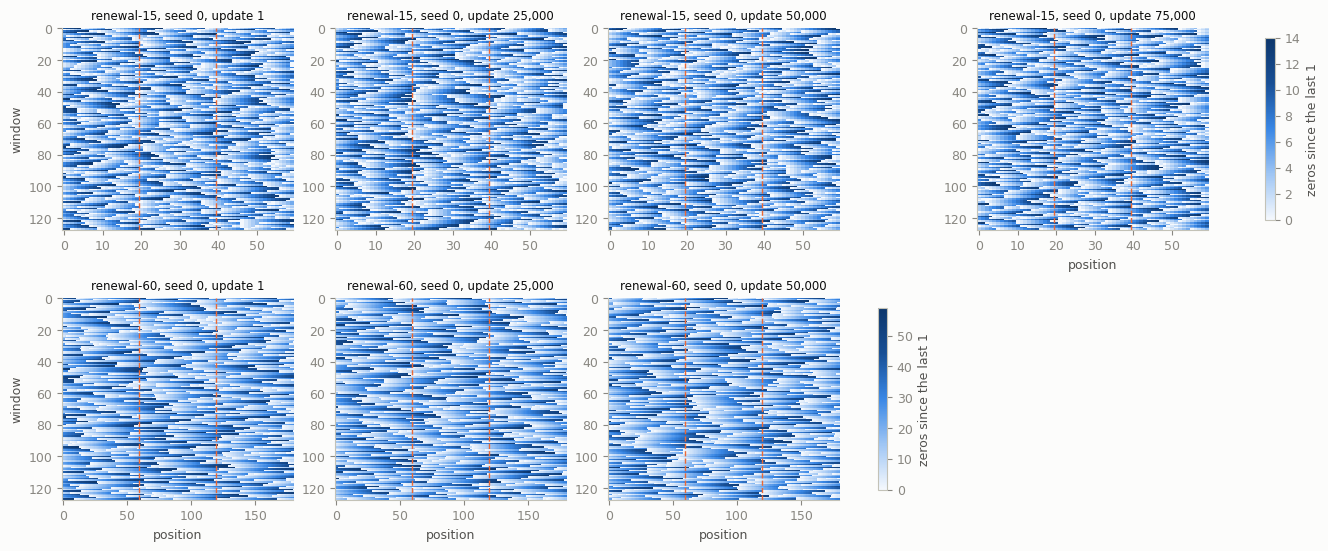

In [11]:
r15 = TR.RUNS / "imported/model_2/renewal-15_w0_s0_section16"
r60 = next(f for f in stream_of("renewal-60_T180_B128_seed1101") if "feedback_GRU" in str(f))
fig = TD.plot_renewal_batches([(r15, [1, 25_000, 50_000, 75_000]), (r60, [1, 25_000, 50_000])])
fig.savefig(FIGURES / "renewal_batches.png", dpi=160, bbox_inches="tight")
plt.show()

### 5.3 The biggest loss jumps

**How a jump is measured**
* A jump is the training loss of one update minus the median loss of the 101 updates around it. The first 101 updates
  are left out: there the loss falls fast for every run.
* "In spreads" divides a jump by the run's typical deviation, 1.4826 × the median absolute deviation. This equals the
  standard deviation when the deviations are normally distributed.
* The batch's exact CE of the same tokens is measured the same way. A jump the batch explains has an exact jump of
  about the same size.

**Two versions**
* The whole training loss, as asked.
* Only its next-token CE terms (the "CE part"). This is the part whose floor is the batch's exact CE; the extra terms
  (model B's copy term, the entropies, the L2 distance) have no such floor.

**What is shown**
1. The three largest jumps of every run, for both versions.
2. The updates at which two or more runs of the same stream had one of their 20 largest CE-part jumps together. They
   saw the same batch, so a shared jump points at the batch.
3. The CE part around the six largest CE-part jumps.
4. The windows of the three largest.

**Results**
* **The whole loss.** Its largest jumps all belong to model B. Its copy term (weight 3) jumps by up to 98 bits on
  renewal-60 while the batch's exact CE barely moves (−1.7 to 2.3 spreads). These spikes come from the model, not the
  data. Over all runs, 56% of the three largest jumps came with a batch at least 3 spreads above its running median.
* **The CE part.** 65% of each run's three largest jumps came with a batch at least 3 spreads above its running
  median, and the median batch jump was 0.99 of the loss jump. Most jumps of the CE part are hard batches.
* **Shared jumps.** On 731 updates, two or more runs of the same stream had one of their 20 largest CE-part jumps
  together. 98.5% of those batches were harder than average, with a median of 3.4 standard deviations above the
  stream's mean exact CE. On update 7,443 of renewal-15 seed 0, 15 of its 19 runs jumped together, on a batch 3.2
  standard deviations harder than average.
* **The eight largest CE jumps (54–84 spreads) are not hard batches.** Their batches moved by at most 2.4 spreads.
  They are spikes in the middle of training (temperature 0.6–2.2): 5b and the discrete Transformer on the flower
  (8, 12) read either way, and C on its backward reading.
  * Some of these runs end close to the true process: the discrete Transformer, 0.0005–0.0085 bits above the
    batch's exact CE over the last 10,000 updates.
  * Others never learn it: C on the backward reading, 0.24 bits above.
* **Three of these eight spikes are each followed by a lasting improvement.** The excess (CE part − the batch's exact
  CE), averaged over 200 updates before and after each spike, fell:
  * from 0.487 to 0.328 bits (5b on the flower (8, 12), update 4,041);
  * from 0.494 to 0.311 bits (the discrete Transformer on it, update 13,412);
  * from 0.308 to 0.007 bits (the same run, update 19,342).

  The other five are brief spikes after which the excess is unchanged (within 0.003 bits).

In [12]:
jumps = {}
for part in ("loss", "ce"):
    rows = []
    for f in WITH_STATS:
        j = TD.loss_jumps(f, STATS[LABEL[f]], part=part)
        j["stream"], j["folder"] = LABEL[f], f
        rows.append(j)
    jumps[part] = pd.concat(rows, ignore_index=True)
show = ["run", "update", "tau", "loss", "jump", "jump_in_spreads", "exact_jump", "exact_jump_in_spreads", "rare_at_handoff"]
for part, what in (("loss", "the whole training loss"), ("ce", "the CE part of the loss")):
    j = jumps[part]
    print(f"{what}: {len(j)} jumps ({len(WITH_STATS)} runs x up to 3); the 10 largest in spreads:")
    display(j.sort_values("jump_in_spreads", ascending=False)[show].head(10).round(3))
    print(f"  share whose batch was at least 3 spreads above its running median: "
          f"{(j['exact_jump_in_spreads'] >= 3).mean():.3f}; median of (batch's exact jump / loss jump): "
          f"{(j['exact_jump'] / j['jump']).median():.3f}")

the whole training loss: 518 jumps (174 runs x up to 3); the 10 largest in spreads:


,run,update,tau,loss,jump,jump_in_spreads,exact_jump,exact_jump_in_spreads,rare_at_handoff
101,B | renewal-60 | w3 | seed 2 | test_models 68c9e49056,21532,1.250,99.243,98.496,14676.096,-0.001,-0.189,0
95,B | renewal-60 | w3 | seed 0 | test_models 3e8e990903,28313,1.005,93.648,92.638,12664.486,-0.012,-1.666,0
102,B | renewal-60 | w3 | seed 2 | test_models 68c9e49056,14192,1.583,83.565,80.691,12023.072,-0.002,-0.328,0
96,B | renewal-60 | w3 | seed 0 | test_models 3e8e990903,7398,1.970,89.373,84.582,11563.065,0.017,2.343,0
103,B | renewal-60 | w3 | seed 2 | test_models 68c9e49056,31378,0.911,67.474,67.239,10018.763,0.001,0.097,0
98,B | renewal-60 | w3 | seed 1 | test_models b25a0c0880,2877,2.279,64.218,63.998,9318.533,-0.007,-0.912,0
99,B | renewal-60 | w3 | seed 1 | test_models b25a0c0880,15794,1.504,62.175,61.896,9012.503,0.001,0.175,0
100,B | renewal-60 | w3 | seed 1 | test_models b25a0c0880,23214,1.184,60.593,60.354,8787.982,0.000,0.049,0
97,B | renewal-60 | w3 | seed 0 | test_models 3e8e990903,2544,2.304,61.491,60.943,8331.388,-0.003,-0.447,0
488,B | renewal-15 | w3 | seed 2 | section 16 (copy_gru_handoff),76080,0.500,71.450,70.911,2122.348,-0.011,-0.733,1


  share whose batch was at least 3 spreads above its running median: 0.573; median of (batch's exact jump / loss jump): 0.934
the CE part of the loss: 518 jumps (174 runs x up to 3); the 10 largest in spreads:


,run,update,tau,loss,jump,jump_in_spreads,exact_jump,exact_jump_in_spreads,rare_at_handoff
41,5b | flower-9 | w0.1 | seed 0 | test_models 8f7ce694be,4041,2.195,11.782,2.244,83.919,0.074,2.414,63
296,discrete_Transformer | flower-13-backward | w0 | seed 1 | test_models f28a59...,34788,0.816,3.782,0.761,79.210,-0.008,-0.754,5
320,discrete_Transformer | flower-9 | w0 | seed 0 | test_models 14333e932d,19342,1.341,4.034,0.726,64.048,-0.003,-0.256,66
293,discrete_Transformer | flower-13-backward | w0 | seed 0 | test_models a6b940...,24079,1.152,3.644,0.619,62.082,0.003,0.257,2
321,discrete_Transformer | flower-9 | w0 | seed 0 | test_models 14333e932d,13412,1.624,4.210,0.703,62.036,-0.017,-1.699,60
110,C | flower-13-backward | w0.01 | seed 2 | test_models 2d1338332c,46322,0.563,21.185,2.348,59.239,-0.011,-0.176,1
104,C | flower-13-backward | w0.01 | seed 0 | test_models e9cce1b147,33797,0.842,21.096,2.298,58.338,0.021,0.339,4
42,5b | flower-9 | w0.1 | seed 0 | test_models 8f7ce694be,28350,1.004,10.664,1.435,53.659,0.046,1.502,63
404,2 | renewal-15 | w0 | seed 1 | section 16 (both_losses),35634,0.794,1.906,0.867,41.274,0.015,0.629,2
317,discrete_Transformer | flower-31-backward | w0 | seed 2 | test_models 20dcd7...,16407,1.474,5.144,0.391,40.370,-0.024,-2.238,2


  share whose batch was at least 3 spreads above its running median: 0.658; median of (batch's exact jump / loss jump): 0.992


In [13]:
by_stream, rows = {}, []
for f in WITH_STATS:
    by_stream.setdefault(LABEL[f], []).append(f)
for label, folders in by_stream.items():
    if len(folders) < 2:
        continue
    tops = {f: set(TD.loss_jumps(f, STATS[label], top=20, apart=50, part="ce")["update"]) for f in folders}
    counts = pd.Series([u for t in tops.values() for u in t]).value_counts()
    exact = STATS[label][1]["exact_mean"]
    for u, n in counts[counts >= 2].items():
        rows.append(dict(stream=label, update=int(u), runs_jumping=int(n), runs_in_stream=len(folders),
                         models=", ".join(sorted(TR.read_settings(f).model for f, t in tops.items() if u in t)),
                         batch_exact_z=float((exact[u - 1] - exact.mean()) / exact.std())))
shared = pd.DataFrame(rows)
print(f"updates where 2 or more runs of a stream had one of their 20 largest CE-part jumps: {len(shared)}; "
      f"batch_exact_z: the batch's exact CE (all tokens) in standard deviations above the stream's mean")
print(f"  median batch_exact_z {shared['batch_exact_z'].median():.2f}; share above 1: "
      f"{(shared['batch_exact_z'] > 1).mean():.3f}; share above 2: {(shared['batch_exact_z'] > 2).mean():.3f}")
display(shared.sort_values(["runs_jumping", "batch_exact_z"], ascending=False).head(15).round(3))

updates where 2 or more runs of a stream had one of their 20 largest CE-part jumps: 752; batch_exact_z: the batch's exact CE (all tokens) in standard deviations above the stream's mean
  median batch_exact_z 3.36; share above 1: 0.979; share above 2: 0.892


,stream,update,runs_jumping,runs_in_stream,models,batch_exact_z
0,renewal-15_T60_B128_seed1101,7443,17,21,"1, 1, 1, 1, 2, 2_L2, 2_L2, 2_L2, 3, 4, 5a, 5b, A, C, de_bruijn, discrete_Tra...",3.218
140,renewal-15_T60_B128_seed1103,28298,15,18,"1, 1, 2, 2_L2, 2_L2, 2_L2, 3, 4, 5a, 5b, A, C, de_bruijn_bic, discrete_Trans...",3.633
1,renewal-15_T60_B128_seed1101,15811,15,21,"1, 1, 2_L2, 2_L2, 2_L2, 3, 4, 5a, 5b, A, C, de_bruijn, de_bruijn_bic, discre...",2.904
2,renewal-15_T60_B128_seed1101,34600,14,21,"2, 2_L2, 2_L2, 2_L2, 3, 4, 5a, 5b, A, C, de_bruijn, de_bruijn_bic, discrete_...",4.156
69,renewal-15_T60_B128_seed1102,41195,14,18,"2, 2_L2, 2_L2, 2_L2, 3, 4, 5a, 5b, A, C, de_bruijn, de_bruijn_bic, discrete_...",3.247
3,renewal-15_T60_B128_seed1101,47424,13,21,"1, 1, 1, 1, 2, 2_L2, 2_L2, 2_L2, 3, 5a, A, B, feedback_GRU",3.225
71,renewal-15_T60_B128_seed1102,8275,12,18,"2, 2_L2, 2_L2, 2_L2, 3, 4, 5a, C, de_bruijn, de_bruijn_bic, discrete_Transfo...",3.729
70,renewal-15_T60_B128_seed1102,20817,12,18,"1, 1, 1, 2, 2_L2, 2_L2, 2_L2, 3, 5a, A, B, de_bruijn",2.983
141,renewal-15_T60_B128_seed1103,21294,12,18,"1, 2, 2_L2, 2_L2, 2_L2, 3, 4, 5a, 5b, A, de_bruijn, feedback_GRU",2.900
72,renewal-15_T60_B128_seed1102,5349,11,18,"2_L2, 2_L2, 4, 5a, 5b, A, C, de_bruijn, de_bruijn_bic, discrete_Transformer,...",3.073


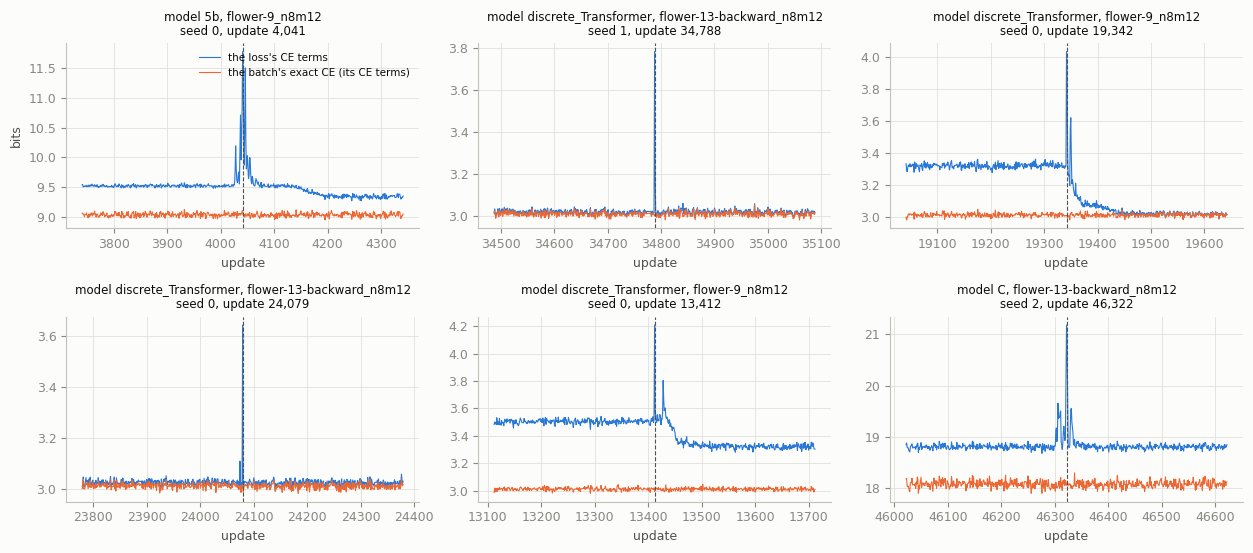

5b | flower-9 | w0.1 | seed 0 | test_models 8f7ce694be
update 4,041 of flower-9_n8m12_T60_B128_seed1101: the first 3 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   7f1j0f7d186f092g1f6i|480h1f7d5h3f2h0f3a59|2h28296a6g1j4i2j6a7h
states 0   08020108020701030207|05010208060403010406|03030307070205030708
tokens 1   6i7f3a5h0i5h284c5g4e|3h7h691c3j680g183j4i|3c682i4a6j5h7h0g3b08
states 1   07080406010603050605|04080702040701020405|04070305070608010401
tokens 2   86f6i0d7f7h6b487i5j3|f6f0i7f6h2j2c0h4f0d3|a6f6f7h187i0g5e3a193
states 2   70707010808070508060|40701080703030105010|40707080208010604020

discrete_Transformer | flower-13-backward | w0 | seed 1 | test_models f28a593987
update 34,788 of flower-13-backward_n8m12_T60_B128_seed1102: the first 3 of its 128 windows; '|' before positions 20, 40
position   01234567890123456789|01234567890123456789|01234567890123456789
tokens 0   7e496g5c1i2h0c2e384f|2i7i1d6d

In [14]:
top = jumps["ce"].sort_values("jump_in_spreads", ascending=False).head(6)
fig = TD.plot_jumps([(r.folder, r.update) for r in top.itertuples()], STATS, part="ce")
fig.savefig(FIGURES / "loss_jumps.png", dpi=160, bbox_inches="tight")
plt.show()
for r in top.head(3).itertuples():
    print(r.run)
    print(TD.show_windows(r.folder, r.update, rows=3), end="\n\n")

## 6. Statistics over training

Every number below counts all the windows of every update up to the last update any run of the stream reached
(50,000, or 75,000 and 100,000 for renewal-15's continued runs).

### 6.1 The true states at each position

Each window starts in a state drawn from the long-run distribution π, and the machine keeps that distribution. So
at every position the true state should follow π.

**The test.** For each stream and position: a chi-square test of the state counts, summed over all updates, against
(windows × π). The windows are independent, so each position's counts are one multinomial sample. If the counts
follow π, about 1% of positions should have p < 0.01. `largest_abs_z` is the largest standardised deviation of any
(position, state) count.

**The rarest states.** The second table gives how many windows per update had one of the rarest states (lowest
long-run probability) at the handoff position, against 128 × their probability.

**Results**
* **The true states follow the long-run distribution at every position.** Of the 2,829 position tests (39 streams),
  12 have p < 0.01. That is 0.4%, where chance gives about 1%. The smallest p is 0.0012, and the largest standardised
  deviation is 4.0.
* **The rarest states come up as often as their probability says.** At the handoff, in seed 0's training:
  * renewal-60's longest count (a59, probability 0.00055) comes up in 0.07 windows per update, 93% of updates have
    none, and the 50,000 updates hold 3,548 such windows in all;
  * renewal-30's a29 comes up in 0.28 windows per update, 76% of updates have none, 13,771 windows in all;
  * renewal-15's a14 comes up in 1.07 windows per update, and 34% of updates have none.

  Each matches 128 × its probability.
* For the forward flowers, every petal state is equally rare, and together they are half of all states, so that row
  says little.

In [15]:
display(pd.DataFrame([TD.state_check(*STATS[label]) for label in STATS]).set_index("stream").round(4))
display(pd.concat([TD.rare_table(*STATS[label]) for label in STATS]).set_index("stream").round(4))

,windows,positions,smallest_p,share_p_below_001,largest_abs_z
stream,,,,,
flower-13-backward_n8m12_T60_B128_seed1101,6400000,61,0.0089,0.0164,3.2001
flower-13-backward_n8m12_T60_B128_seed1102,6400000,61,0.0064,0.0164,3.3768
flower-13-backward_n8m12_T60_B128_seed1103,6400000,61,0.0179,0.0000,3.5397
flower-15-backward_n8m14_T60_B128_seed1101,6400000,61,0.0088,0.0328,3.5247
flower-15-backward_n8m14_T60_B128_seed1102,6400000,61,0.0158,0.0000,3.0350
flower-15-backward_n8m14_T60_B128_seed1103,6400000,61,0.0333,0.0000,3.3468
flower-21_n20m30_T60_B128_seed1101,6400000,61,0.0083,0.0164,3.8408
flower-21_n20m30_T60_B128_seed1102,6400000,61,0.0062,0.0164,3.5851
flower-21_n20m30_T60_B128_seed1103,6400000,61,0.0052,0.0164,3.6838


,rarest_states,probability,position,mean_per_update,expected_per_update,share_of_updates_with_none,expected_share_with_none,total
stream,,,,,,,,
flower-13-backward_n8m12_T60_B128_seed1101,s2,0.0234,40,2.9857,2.9894,0.0479,0.0486,149286
flower-13-backward_n8m12_T60_B128_seed1102,s2,0.0234,40,2.9917,2.9894,0.0497,0.0486,149583
flower-13-backward_n8m12_T60_B128_seed1103,s2,0.0234,40,2.9903,2.9894,0.0503,0.0486,149514
flower-15-backward_n8m14_T60_B128_seed1101,s5,0.0163,40,2.0882,2.0882,0.1207,0.1218,104412
flower-15-backward_n8m14_T60_B128_seed1102,s5,0.0163,40,2.0880,2.0882,0.1227,0.1218,104400
flower-15-backward_n8m14_T60_B128_seed1103,s5,0.0163,40,2.0814,2.0882,0.1233,0.1218,104069
flower-21_n20m30_T60_B128_seed1101,"s1, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, s12, s13, s14, s15, s16, s17, ...",0.5000,40,63.9592,64.0000,0.0000,0.0000,3197961
flower-21_n20m30_T60_B128_seed1102,"s1, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, s12, s13, s14, s15, s16, s17, ...",0.5000,40,64.0053,64.0000,0.0000,0.0000,3200267
flower-21_n20m30_T60_B128_seed1103,"s1, s2, s3, s4, s5, s6, s7, s8, s9, s10, s11, s12, s13, s14, s15, s16, s17, ...",0.5000,40,64.0070,64.0000,0.0000,0.0000,3200350


### 6.2 Repeated windows

**How repeats are counted**
* Two windows are equal when all their tokens are equal. They are compared exactly, as packed bytes.
* A "repeat" is a window equal to an earlier one.
* The expected number of equal pairs is (number of pairs) × Σ_w P(w)²: the chance that two independent windows are
  equal, computed exactly from the generating machine. A test checks it against listing every word.

The same is done for the first H tokens of each window: the history the hybrids' Transformer reads before the
handoff.

**Results**
* **The counts match the process.** Wherever pairs are common, the number of equal pairs is within about 1% of the
  process's prediction (ratios 0.994–1.010). Renewal-5's whole windows have only 2–12 pairs against 9.5 expected,
  which agrees within chance.
* **How often whole windows repeat depends on the entropy rate.** No flower window or history ever repeats. The share
  of windows that repeat an earlier one is:
  * 0.0% for renewal-5;
  * 0.3% for renewal-10;
  * 11–13% for renewal-15;
  * 16% for renewal-30 (90 tokens);
  * 3% for renewal-60 (180 tokens).
* **The histories before the handoff repeat much more:** 72–74% of renewal-15's, 70.5% of renewal-30's and 44% of
  renewal-60's. The most common 40-token history of renewal-15 came up 3,203–4,300 times.

In [16]:
rows = []
for label, (info, _) in STATS.items():
    parts = [("whole window", info["windows"])] + [(f"first {H} tokens", h) for H, h in info["histories"].items()]
    for part, r in parts:
        rows.append(dict(stream=label, part=part, windows=r["windows"], different=r["different"],
                         share_repeated=r["repeats"] / r["windows"], equal_pairs=r["equal_pairs"],
                         expected_equal_pairs=r["expected_equal_pairs"],
                         observed_over_expected=r["equal_pairs"] / r["expected_equal_pairs"]
                         if r["expected_equal_pairs"] > 1e-9 else np.nan, most_seen=r["max_count"]))
repeats = pd.DataFrame(rows).set_index(["stream", "part"])
display(repeats.round(4))
info = STATS["renewal-5_T60_B128_seed1101"][0]["windows"]
print("renewal-5, seed 0: the most common whole windows (count, tokens):")
for c, w in zip(info["top_counts"][:5], info["top_tokens"][:5]):
    print(f"  {c:>4}  {''.join(map(str, w))}")

windows  different  share_repeated  equal_pairs  expected_equal_pairs  observed_over_expected  most_seen
stream                                     part                                                                                                                      
flower-13-backward_n8m12_T60_B128_seed1101 whole window      6400000    6400000          0.0000          0.0          0.000000e+00                     NaN          1
                                           first 40 tokens   6400000    6400000          0.0000          0.0          0.000000e+00                     NaN          1
flower-13-backward_n8m12_T60_B128_seed1102 whole window      6400000    6400000          0.0000          0.0          0.000000e+00                     NaN          1
                                           first 40 tokens   6400000    6400000          0.0000          0.0          0.000000e+00                     NaN          1
flower-13-backward_n8m12_T60_B128_seed1103 whole window      6400000    6400000          0.0000          0.0          0.000000e+00                     NaN          1
...                                                              ...        ...             ...          ...                   ...                     ...        ...
renewal-60_T180_B128_seed1101              first 120 tokens  6400000    3557640          0.4441  164086082.0          1.638698e+08                  1.0013        966
renewal-60_T180_B128_seed1102              whole window      6400000    6188689          0.0330     497907.0          4.964451e+05                  1.0029         25
                                           first 120 tokens  6400000    3555768          0.4444  164326264.0          1.638698e+08                  1.0028        923
renewal-60_T180_B128_seed1103              whole window      6400000    6188327          0.0331     499552.0          4.964451e+05                  1.0063         23
                                           first 120 tokens  6400000    3556704          0.4443  164006557.0          1.638698e+08                  1.0008        987

[78 rows x 7 columns]

renewal-5, seed 0: the most common whole windows (count, tokens):
     2  000100010001000010000100001100010001000010000100001000010000
     2  010100001000010000100001100010000100010000100001000100100001
     2  000100001110010000100100001000010001000100001000010000100001
     2  100001001000010000110000100001000010000100110000111000100001
     2  010010011000011001000010001000110001000010000100001010000100


### 6.3 How many different histories were seen

A word of L tokens is any L consecutive tokens of a window, and every position of every window counts. (This is the
de Bruijn models' node when L = R, which they count on windows of their own before training.) For each stream and
L:
* the number of different words seen in training;
* how often each was seen;
* the share of the test windows' words that were seen in training at least once. These are the 4,096 windows, seed
  4404, that `analysis.py`'s test results use.

A length is no longer counted once more than 20 million different words of it have been seen.

**Results**
* **Short words are all seen.** For every renewal process, at least 99.95% of the test windows' words of up to 20
  tokens appeared in training, and so did every flower's words of up to 4 tokens.
* **Coverage falls only for long words.** 94% of renewal-15's 40-token words were seen (seed 0), and 96% of
  renewal-10's 32-token words.
* **At the de Bruijn models' orders**, 99.6–100% of the test words were seen. For renewal-60 (R = 59) the share is
  99.65%, and 99.0% were seen at least 10 times.
* Lengths with more than 20 million different words were not counted: beyond 5 tokens for the 50-token flowers.
* The seeds differ by at most 0.0018.

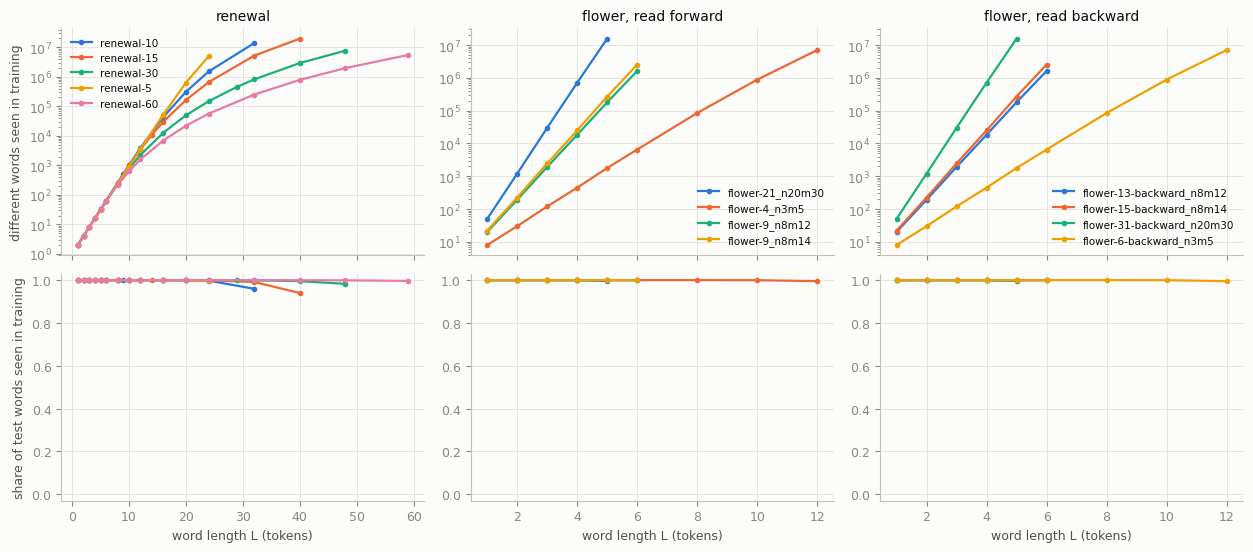

Share of the test windows' words of L tokens seen at least once in training (seed 0; empty: not counted):


L,1,2,3,4,5,6,8,9,10,12,14,16,20,24,29,32,40,48,59
stream,,,,,,,,,,,,,,,,,,,
flower-13-backward_n8m12_T60_B128_seed1101,1.0,1.0,1.0,1.0,1.000,0.9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flower-15-backward_n8m14_T60_B128_seed1101,1.0,1.0,1.0,1.0,1.000,0.9998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flower-21_n20m30_T60_B128_seed1101,1.0,1.0,1.0,1.0,0.996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flower-31-backward_n20m30_T60_B128_seed1101,1.0,1.0,1.0,1.0,0.996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flower-4_n3m5_T60_B128_seed1101,1.0,1.0,1.0,1.0,1.000,1.0000,1.0,NaN,0.9997,0.9954,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flower-6-backward_n3m5_T60_B128_seed1101,1.0,1.0,1.0,1.0,1.000,1.0000,1.0,NaN,0.9997,0.9953,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flower-9_n8m12_T60_B128_seed1101,1.0,1.0,1.0,1.0,1.000,0.9997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flower-9_n8m14_T60_B128_seed1101,1.0,1.0,1.0,1.0,1.000,0.9997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
renewal-10_T60_B128_seed1101,1.0,1.0,1.0,1.0,1.000,1.0000,1.0,1.0,1.0000,1.0000,NaN,1.0,0.9996,0.9975,NaN,0.9595,NaN,NaN,NaN


Spread over seeds: the largest difference between seeds 0, 1 and 2 of the same process, any L:


,largest seed difference
process,
flower-13-backward_n8m12_T60,0.0001
flower-15-backward_n8m14_T60,0.0001
flower-21_n20m30_T60,0.0003
flower-31-backward_n20m30_T60,0.0002
flower-4_n3m5_T60,0.0002
flower-6-backward_n3m5_T60,0.0003
flower-9_n8m12_T60,0.0000
flower-9_n8m14_T60,0.0000
renewal-10_T60,0.0015


In [17]:
coverage_groups = {"renewal": {}, "flower, read forward": {}, "flower, read backward": {}}
for label, (info, _) in sorted(STATS.items()):
    if info["train_seed"] == 1101:
        coverage_groups[group_of(label)][label.split("_T")[0]] = info
fig = TD.plot_coverage(coverage_groups)
fig.savefig(FIGURES / "histories_seen.png", dpi=160, bbox_inches="tight")
plt.show()
rows = []
for label, (info, _) in STATS.items():
    counts = {r["L"]: r for r in info["word_counts"]}
    for r in info["coverage"]:
        if r["kind"] == "test":
            c = counts[r["L"]]
            rows.append(dict(stream=label, L=r["L"], different=c["different"], seen_once=c.get("words_seen_1"),
                             test_words_seen=r.get("seen"), test_words_seen_10_times=r.get("seen_10")))
coverage = pd.DataFrame(rows)
print("Share of the test windows' words of L tokens seen at least once in training (seed 0; empty: not counted):")
display(coverage[coverage.stream.str.endswith("seed1101")].pivot(index="stream", columns="L", values="test_words_seen")
        .round(4))
print("Spread over seeds: the largest difference between seeds 0, 1 and 2 of the same process, any L:")
coverage["process"] = coverage.stream.str.replace(r"_B\d+_seed\d+$", "", regex=True)
spread = coverage.groupby(["process", "L"])["test_words_seen"].agg(lambda v: v.max() - v.min()).groupby("process").max()
display(spread.round(4).to_frame("largest seed difference"))

### 6.4 The training loss and what each batch contained

Every CE term of the training loss is a mean over the batch's tokens, so it moves from update to update for two
reasons: the model changes, and the batch changes. The batch's exact CE of the same tokens measures the second
reason alone, because it is what a model that knows the process would score on that batch.

For every run, CE term and phase of training, the table gives the median, over a model's runs, of:
* `explained`: the share of the term's update-to-update variance that goes with the batch's exact CE (the squared
  correlation);
* `excess`: the mean of (term − exact CE).

The figure shows six runs' terms against the batch's exact CE over the last 10,000 updates.

**Results**
* **Early on, the batch accounts for almost nothing.** In the first 1,000 updates the median share is 1% over all
  run-terms: the loss falls with learning.
* **Later, it accounts for most.** The median share is 92% over updates 1,001–10,000 and 96% over the last 10,000
  updates (234 run-terms with at least 10,000 updates; 75% of them above 0.9).
* **The share follows how well the model learned.** Over the last 10,000 updates, the rank correlation between a
  term's mean excess (term − exact CE) and its share is −0.87. The median share by mean excess:
  * within 0.01 bits: 0.993;
  * 0.01–0.05 bits: 0.944;
  * 0.05–0.1 bits: 0.805;
  * more than 0.1 bits: 0.614.
* **The lowest shares belong to runs that did not learn their process:**
  * C on the backward flower (8, 12): 0.01–0.06, with an excess of 0.24 bits;
  * the discrete Transformer on the backward flower (20, 30): 0.003–0.27;
  * 5b on the flowers: 0.18–0.69;
  * the feedback GRU on the flower (20, 30): 0.49–0.67.
* **The de Bruijn models follow the batch most closely:** 0.9999 with the Markov order and 0.995 with the fitted
  order.
* **The excess is much steadier than the term.** For the 186 run-terms within 0.05 bits of the exact CE, the excess
  (term − exact CE) varies from update to update a median 5.8 times less than the term itself (quartiles 4.1–14.8);
  for 5a's `ce_t1`, 0.0018 against 0.0105 bits. A training curve of the excess is therefore much less noisy than one of
  the loss.

In [18]:
parts = []
for f in WITH_STATS:
    part = TD.loss_vs_content(f, STATS[LABEL[f]])
    part["process"] = LABEL[f].split("_T")[0]
    parts.append(part)
content = pd.concat(parts, ignore_index=True)
order = [p for p, _, _ in TD.PHASES]
summary = content.groupby(["model", "term", "phase"])[["explained", "mean_excess"]].median().unstack("phase")
display(summary.reindex(columns=order, level=1).round(3))
by_process = content[content.phase == order[-1]].groupby(["process", "model", "term"])["explained"].median().unstack("model")
print("Last 10,000 updates: the median share explained, by process and model (rows: process and term):")
display(by_process.round(3))

explained                                                  mean_excess                                         
phase                       first 1,000 updates updates 1,001-10,000 last 10,000 updates first 1,000 updates updates 1,001-10,000 last 10,000 updates
model                term                                                                                                                            
1                    ce_gru               0.028                0.866               0.931               0.072                0.034               0.046
2                    ce_gru               0.012                0.863               0.908               0.070                0.033               0.041
                     ce_t1                0.009                0.957               0.942               0.044                0.010               0.005
2_L2                 ce_gru               0.029                0.878               0.935               0.070                0.036               0.045
                     ce_t1                0.013                0.960               0.955               0.044                0.012               0.007
3                    ce_gru               0.029                0.851               0.944               0.070                0.035               0.025
                     ce_t1                0.013                0.951               0.948               0.046                0.018               0.006
4                    ce_t1                0.014                0.918               0.932               0.046                0.008               0.004
5a                   ce_gru               0.028                0.856               0.947               0.070                0.033               0.043
                     ce_t1                0.013                0.965               0.970               0.044                0.009               0.001
                     ce_t2                0.008                0.959               0.979               0.106                0.015               0.002
5b                   ce_t1                0.002                0.008               0.774               0.502                0.189               0.024
                     ce_t2                0.000                0.179               0.938               0.663                0.194               0.026
A                    ce_gru               0.029                0.857               0.820               0.069                0.031               0.012
                     ce_t1                0.013                0.937               0.955               0.045                0.011               0.004
B                    ce_gru               0.002                0.053               0.962               0.449                0.084               0.015
C                    ce_t1                0.002                0.546               0.865               0.343                0.063               0.004
                     ce_t2                0.002                0.900               0.957               0.459                0.068               0.004
                     ce_t3                0.002                0.924               0.975               0.606                0.076               0.006
de_bruijn            pred                 0.999                1.000               1.000               0.000                0.000               0.000
de_bruijn_bic        pred                 0.970                0.989               0.995               0.004                0.002               0.001
discrete_Transformer ce                   0.001                0.013               0.941               0.529                0.125               0.011
feedback_GRU         ce                   0.001                0.035               0.926               0.416                0.091               0.019

Last 10,000 updates: the median share explained, by process and model (rows: process and term):


model                                 1      2   2_L2      3      4     5a     5b      A      B      C  de_bruijn  de_bruijn_bic  discrete_Transformer  feedback_GRU
process                   term                                                                                                                                      
flower-13-backward_n8m12  ce        NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN        NaN            NaN                 0.968         0.897
                          ce_gru    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  0.965    NaN        NaN            NaN                   NaN           NaN
                          ce_t1     NaN    NaN    NaN    NaN    NaN    NaN  0.949    NaN    NaN  0.047        NaN            NaN                   NaN           NaN
                          ce_t2     NaN    NaN    NaN    NaN    NaN    NaN  0.986    NaN    NaN  0.683        NaN            NaN                   NaN           NaN
                          ce_t3     NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  0.889        NaN            NaN                   NaN           NaN
flower-15-backward_n8m14  pred      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN      0.993          0.993                   NaN           NaN
flower-21_n20m30          ce        NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN        NaN            NaN                 0.709         0.619
                          ce_gru    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  0.805    NaN        NaN            NaN                   NaN           NaN
                          ce_t1     NaN    NaN    NaN    NaN    NaN    NaN  0.687    NaN    NaN    NaN        NaN            NaN                   NaN           NaN
                          ce_t2     NaN    NaN    NaN    NaN    NaN    NaN  0.920    NaN    NaN    NaN        NaN            NaN                   NaN           NaN
flower-31-backward_n20m30 ce        NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN        NaN            NaN                 0.268         0.810
                          ce_gru    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  0.711    NaN        NaN            NaN                   NaN           NaN
                          ce_t1     NaN    NaN    NaN    NaN    NaN    NaN  0.420    NaN    NaN    NaN        NaN            NaN                   NaN           NaN
                          ce_t2     NaN    NaN    NaN    NaN    NaN    NaN  0.855    NaN    NaN    NaN        NaN            NaN                   NaN           NaN
flower-4_n3m5             pred      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN      0.998          0.998                   NaN           NaN
flower-6-backward_n3m5    pred      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN      0.998          0.998                   NaN           NaN
flower-9_n8m12            ce        NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN        NaN            NaN                 0.977         0.997
                          ce_gru    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  0.997    NaN        NaN            NaN                   NaN           NaN
                          ce_t1     NaN    NaN    NaN    NaN    NaN    NaN  0.502    NaN    NaN  0.754        NaN            NaN                   NaN           NaN
                          ce_t2     NaN    NaN    NaN    NaN    NaN    NaN  0.818    NaN    NaN  0.934        NaN            NaN                   NaN           NaN
                          ce_t3     NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  0.969        NaN            NaN                   NaN           NaN
flower-9_n8m14            pred      NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN      0.995          0.995                   NaN           NaN
renewal-10                pred      NaN 

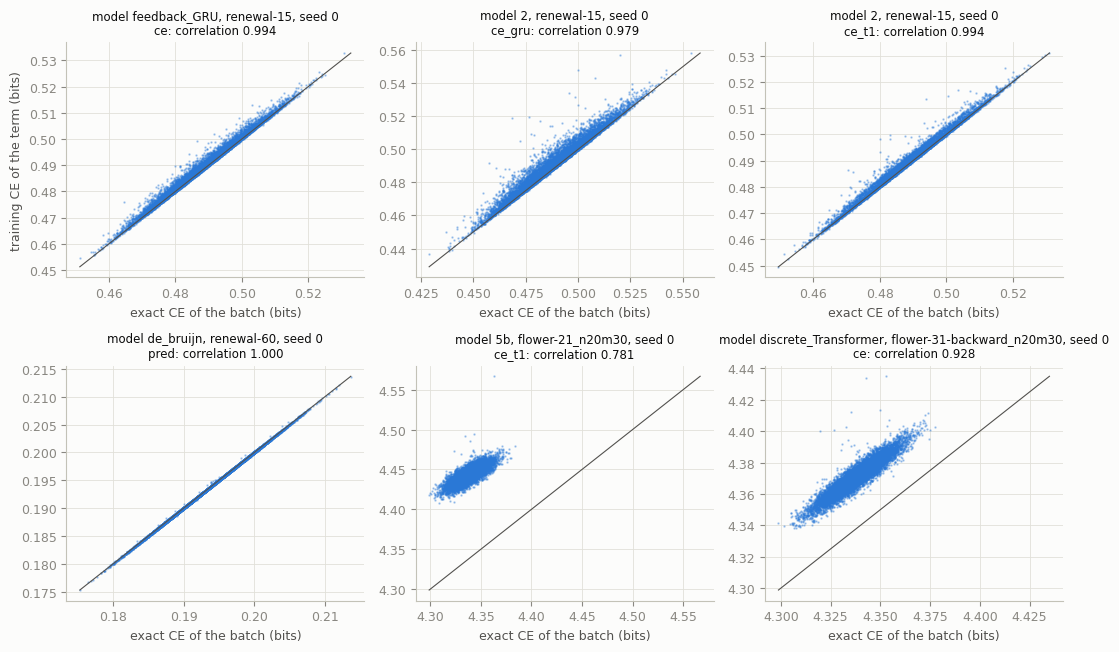

In [19]:
def pick(label, model, term, source=None):
    folders = [f for f in WITH_STATS if LABEL[f] == label and TR.read_settings(f).model == model
               and (source is None or source in str(f))]
    return (folders[0], term) if folders else None


cases = [c for c in (pick("renewal-15_T60_B128_seed1101", "feedback_GRU", "ce"),
                     pick("renewal-15_T60_B128_seed1101", "2", "ce_gru", "section16"),
                     pick("renewal-15_T60_B128_seed1101", "2", "ce_t1", "section16"),
                     pick("renewal-60_T180_B128_seed1101", "de_bruijn", "pred"),
                     pick("flower-21_n20m30_T60_B128_seed1101", "5b", "ce_t1"),
                     pick("flower-31-backward_n20m30_T60_B128_seed1101", "discrete_Transformer", "ce")) if c]
if cases:
    fig = TD.plot_loss_vs_content(cases, STATS)
    fig.savefig(FIGURES / "loss_vs_batch.png", dpi=160, bbox_inches="tight")
    plt.show()

## 7. Findings

1. **The training data of every update can be found again exactly**, with `TD.windows_at(run, update)`. It was
   checked on every saved run whose sampler state was saved: 170 of 171 (section 2). Runs with the same process,
   seed, batch size and window length saw the same windows, whatever their model (section 3).
2. **The data are what the process says.** Every position's true states follow the long-run distribution, and
   repeats match the predicted rate (6.1, 6.2). Even the rarest states are seen as often as their probability says:
   renewal-60's longest count is at the handoff in 3,548 windows over training, though in only 7% of updates (6.1).
   A model that fails to learn such a state lacks updates that contain it, not data overall.
3. **Every first scored token comes after the point where the true state is known from the tokens**, in every
   process (section 4). Almost every short context of the test windows was seen in training (6.3).
4. **Once a model has learned, its training loss moves with the batch** (6.4). One update's loss says more about
   that batch than about the model. To follow training, use the excess over the batch's exact CE (this notebook's
   `TD.run_exact`): for trained models it is a median 5.8 times steadier than the loss term.
5. **Jumps.**
   * Most jumps of the CE part come from hard batches. They are shared by the runs that saw the same batch: up to 15
     of 19 runs on one update (5.3).
   * The largest jumps are the model's own: model B's copy term (up to 98 bits), and spikes in the middle of training
     of 5b, C and the discrete Transformer on the flower (8, 12) (5.3).
   * Three of the eight largest CE spikes are each followed by a lasting fall of the excess (for example 0.308 →
     0.007 bits for the discrete Transformer). There a spike marks the model changing its states and then predicting
     better.

## References

* Melissa E. O'Neill (2014). *PCG: A Family of Simple Fast Space-Efficient Statistically Good Algorithms for Random
  Number Generation.* Harvey Mudd College, technical report HMC-CS-2014-0905 (pcg-random.org/paper.html; the site
  lists "jump ahead" among the generators' features).
* NumPy documentation: `numpy.random.PCG64.advance` ("Advance the underlying RNG as-if delta draws have occurred").
* `walkthrough.ipynb`, section 4: what a run folder stores.